# Decision tree

In [11]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [12]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

In [13]:
data = load_iris()
X = data.data
y = data.target

In [14]:
df = pd.DataFrame(X, columns=data.feature_names)

In [15]:
df['target'] = y

In [17]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [22]:
df['species'] = pd.Categorical.from_codes(data.target, data.target_names)

In [23]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


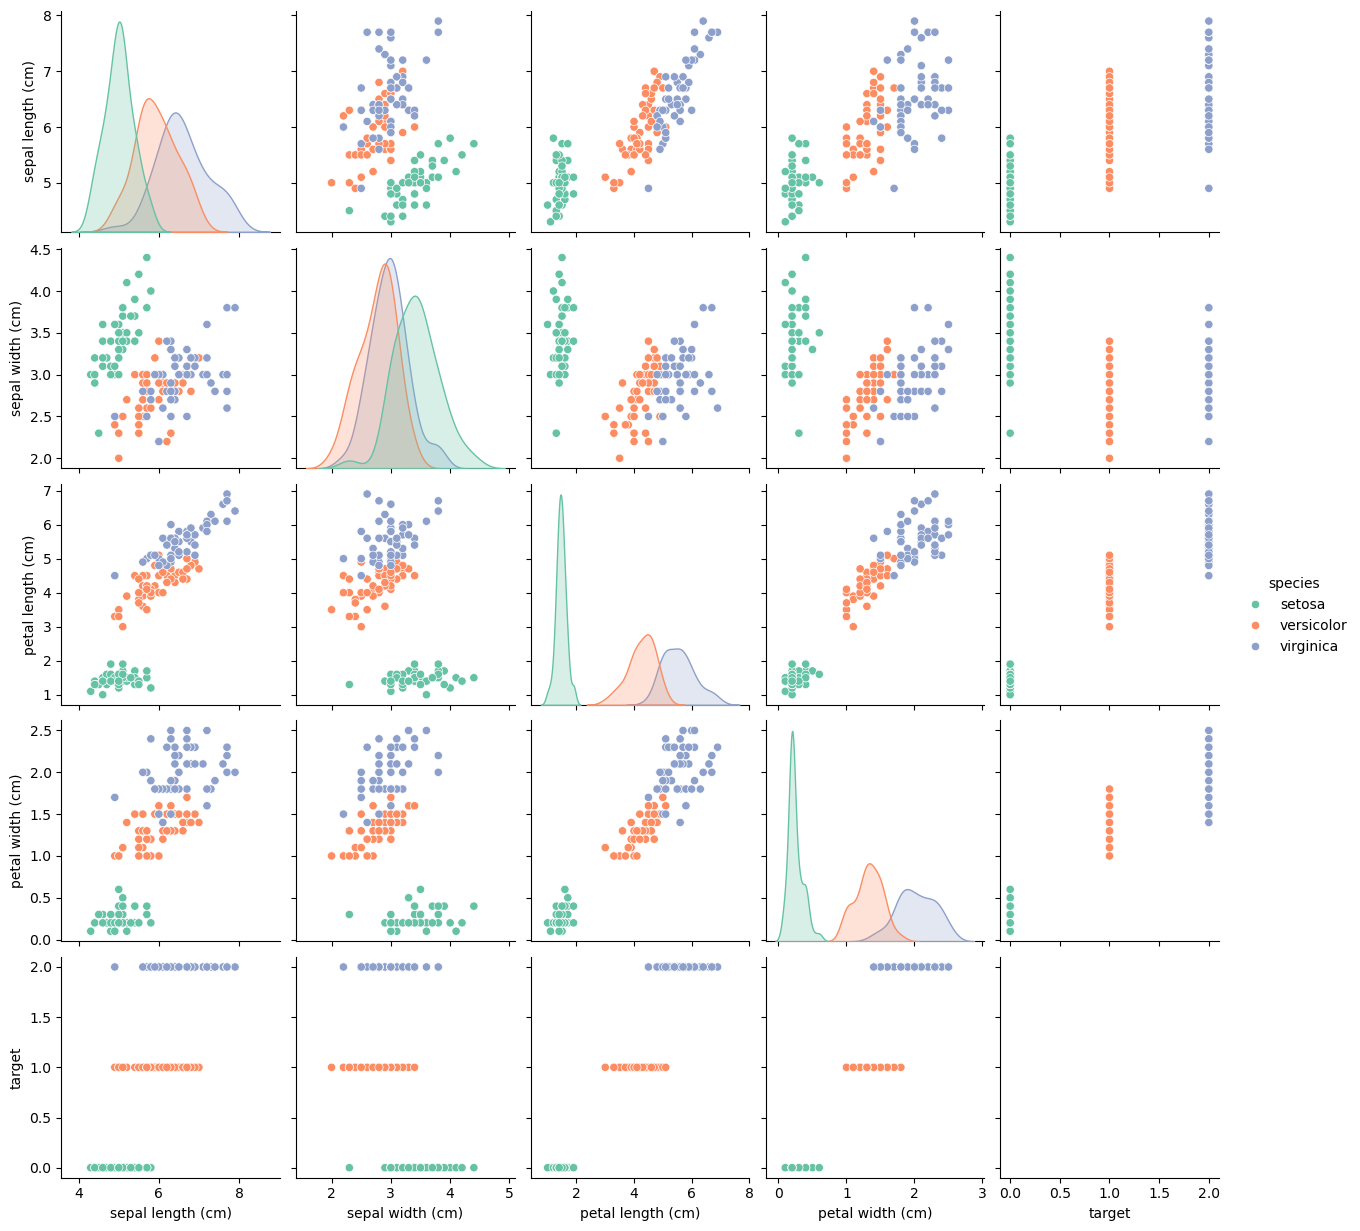

In [24]:
sns.pairplot(df, hue= 'species', palette='Set2')

In [25]:
# Split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

In [26]:
clf = DecisionTreeClassifier(max_depth=3, random_state=42)

In [27]:
clf.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=3, random_state=42)

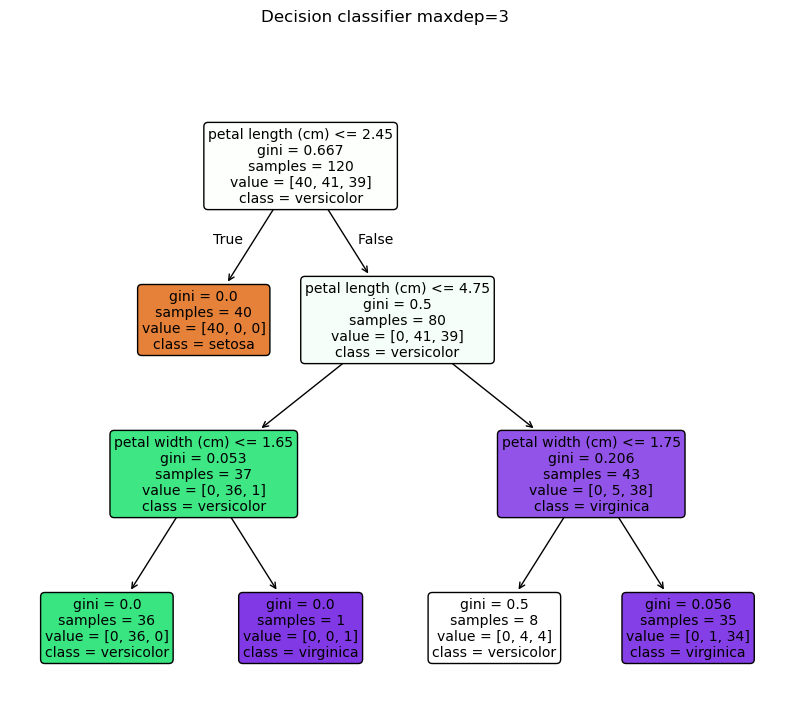

In [29]:
plt.figure(figsize=(10,8))
plot_tree(clf, feature_names=data.feature_names, class_names=data.target_names,
         filled=True, rounded=True)
plt.suptitle('Decision classifier maxdep=3')
plt.show()

In [30]:
y_pred = clf.predict(X_test)

In [32]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [33]:
confusion_matrix(y_test, y_pred)

array([[10,  0,  0],
       [ 0,  9,  0],
       [ 0,  0, 11]], dtype=int64)

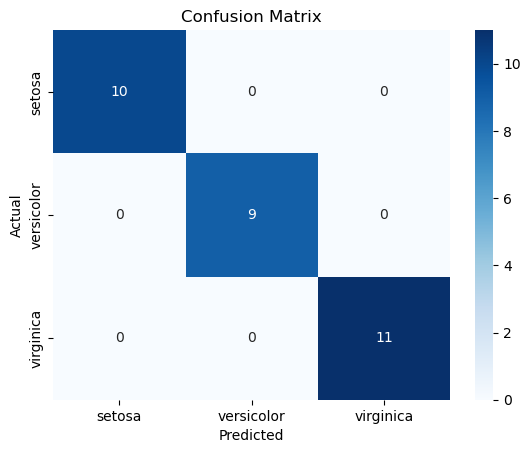

In [37]:
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, cmap='Blues',
            xticklabels=data.target_names, yticklabels=data.target_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

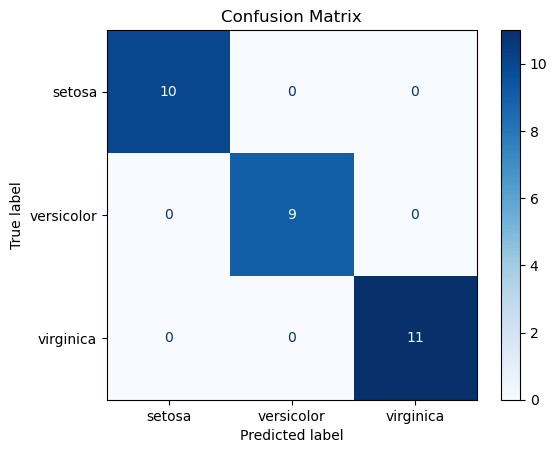

In [38]:
cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)

# Display confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=data.target_names)
disp.plot(cmap='Blues')  # optional: color map
plt.title("Confusion Matrix")
plt.show()

# Overfitting vs underfitting

In [40]:
from sklearn.model_selection import GridSearchCV
param_grid = {
    'max_depth': [2, 3, 4, 5],
    'min_samples_split': [2, 4, 6]
}
grid = GridSearchCV(DecisionTreeClassifier(), param_grid, cv=5)
grid.fit(X_train, y_train)
print("Best Parameters:", grid.best_params_)
print("Best Score:", grid.best_score_)

Best Parameters: {'max_depth': 4, 'min_samples_split': 2}
Best Score: 0.9416666666666668


In [41]:
logreg = LogisticRegression(max_iter=200)
logreg.fit(X_train, y_train)
logreg_preds = logreg.predict(X_test)

print("Logistic Regression Accuracy:", accuracy_score(y_test, logreg_preds))

Logistic Regression Accuracy: 1.0
